# Inference – GT bins and GT correspondences

Same cell order, pose metrics and plots as `inference_pose.ipynb`.
Select `CHECKPOINT_DIR` below. The notebook reads input channels and training
settings from the checkpoint: it supports the original 3-channel GT-bin run,
and both 4-channel runs (with GT correspondences or with a zero match channel).

For RGB-trained checkpoints use your ordinary inference notebook instead.
No external training script is required; GT preprocessing is included here.


In [4]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

from dataset import SceneTwoPairsDataset
from model_pose import PairImageCylinderModel
from utils import plot_relative_pose, pose_to_text

# Match the architecture used during training.
IMG_SIZE = 128
PATCH_SIZE = (16, 4)
NUM_BINS = 128
EMBED_DIM = 192
DEPTH = 4
NUM_HEADS = 4
DROPOUT = 0.1

CHECKPOINT_DIR = Path("arrhenius_runs/slurm_long_run_gt_bins_corr/checkpoints")

GT_BINS_INPUT = True  # This notebook evaluates GT-bin-trained checkpoints only.

MODEL_VERSION = "best"  # "best" eller "latest"

CHECKPOINT = CHECKPOINT_DIR / f"{MODEL_VERSION}.pt"

TEST_DATASET = Path("valdataset")
INFERENCE_BATCH_SIZE = 4
VISION_SAMPLE_IDX = 0
INFERENCE_SHOW_TEXT = False
INFERENCE_SHOW_IMAGES = True
OCC_THRESHOLD = 0.2  # Same threshold used in train_v2 inference plots.

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_float32_matmul_precision("high")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Test dataset:", TEST_DATASET)


Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
Test dataset: valdataset


In [5]:
import torch.nn.functional as F

def gt_bins_to_input(vision, image_size, correspondence=None):
    """GT geometry + correspondence [B, other_bins, current_bins] -> 4 channels."""
    occupied = (vision[..., 0] > 0.5).float()
    radius = vision[..., 1].float().clamp_min(0)
    depth = vision[..., 2].float().clamp_min(0)
    features = torch.stack([
        occupied,
        torch.log1p(radius) * occupied,
        torch.log1p(depth) * occupied,
    ], dim=1).unsqueeze(2)
    
    geometry = F.interpolate(
        features, size=(image_size, image_size), mode="nearest"
    )
    if correspondence is None:
        return geometry
    correspondence = F.interpolate(
        correspondence.float().unsqueeze(1),
        size=(image_size, image_size),
        mode="nearest",
    )
    return torch.cat([geometry, correspondence], dim=1)


def gt_correspondence_maps(vision_a, vision_b):
    """Return maps for A and B, using occupied GT bins with identical IDs.

    matches[b, ia, ib] is True exactly when A bin ia and B bin ib belong
    to the same cylinder. Occupancy excludes empty bins even if their ID is 0.
    This also supports a cylinder covering multiple bins.
    """
    occ_a = vision_a[..., 0] > 0.5
    occ_b = vision_b[..., 0] > 0.5
    ids_a = vision_a[..., 3].round().long()
    ids_b = vision_b[..., 3].round().long()
    matches = (
        (ids_a.unsqueeze(2) == ids_b.unsqueeze(1))
        & occ_a.unsqueeze(2)
        & occ_b.unsqueeze(1)
    )
    # Geometry varies along x. Keep x associated with the current view.
    map_a = matches.transpose(1, 2)  # y = B bins, x = A bins
    map_b = matches                  # y = A bins, x = B bins
    return map_a, map_b


def predict_pose_from_gt_bins(model, vision_a, vision_b):
    patch_embed = model.backbone.patch_embed
    image_size = patch_embed.grid_h * patch_embed.patch_h
    if patch_embed.proj.in_channels == 3:
        input_a = gt_bins_to_input(vision_a, image_size)
        input_b = gt_bins_to_input(vision_b, image_size)
        camera_a, camera_b, patches_a, patches_b = model.backbone(input_a, input_b)
        return model.pose_head(camera_a, camera_b, patches_a, patches_b)
    if vision_a.shape[1] != image_size or vision_b.shape[1] != image_size:
        raise ValueError("4-channel runs require one bin per input pixel column.")
    map_a, map_b = gt_correspondence_maps(vision_a, vision_b)
    if not getattr(model, "use_gt_correspondences", True):
        map_a = torch.zeros_like(map_a)
        map_b = torch.zeros_like(map_b)
    input_a = gt_bins_to_input(vision_a, image_size, map_a)
    input_b = gt_bins_to_input(vision_b, image_size, map_b)
    camera_a, camera_b, patches_a, patches_b = model.backbone(input_a, input_b)
    
    return model.pose_head(camera_a, camera_b, patches_a, patches_b)


def load_gt_pose_checkpoint(path, device):
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    saved_args = checkpoint.get("args", {})
    state = checkpoint["model_state_dict"]
    in_chans = state["backbone.patch_embed.proj.weight"].shape[1]
    if in_chans not in (3, 4):
        raise ValueError(f"Unsupported input channel count: {in_chans}")
    model = PairImageCylinderModel(
        img_size=saved_args.get("img_size", IMG_SIZE),
        patch_size=tuple(saved_args.get("patch_size", PATCH_SIZE)),
        in_chans=in_chans,
        embed_dim=saved_args.get("embed_dim", EMBED_DIM),
        depth=saved_args.get("depth", DEPTH),
        num_heads=saved_args.get("num_heads", NUM_HEADS),
        num_bins=saved_args.get("num_bins", NUM_BINS),
        dropout=saved_args.get("dropout", DROPOUT),
    ).to(device)
    model.use_gt_correspondences = bool(saved_args.get("gt_correspondences", True)) if in_chans == 4 else False
    model.load_state_dict(state, strict=True)
    model.eval()
    condition = (
        "GT bins, 3 channels" if in_chans == 3 else
        "GT bins + GT correspondences, 4 channels" if model.use_gt_correspondences else
        "GT bins + zero correspondence channel, 4 channels"
    )
    print(f"Loaded checkpoint: {path}")
    print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))
    print("Condition:", condition)
    print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
    return model, checkpoint


model, checkpoint = load_gt_pose_checkpoint(CHECKPOINT, DEVICE)
history = checkpoint.get("history")


Loaded checkpoint: arrhenius_runs/slurm_long_run_gt_bins_corr/checkpoints/best.pt
Checkpoint epoch: 90
Condition: GT bins + GT correspondences, 4 channels
Model parameters: 4,595,593


In [6]:
# Fixed ordering makes sample plots comparable between checkpoints.
infer_dataset = SceneTwoPairsDataset(
    root_dir=str(TEST_DATASET),
    return_two_pairs=False,
    image_size=checkpoint.get("args", {}).get("img_size", IMG_SIZE),
)
infer_loader = DataLoader(
    infer_dataset,
    batch_size=INFERENCE_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)
print("Inference dataset size:", len(infer_dataset))


Inference dataset size: 482


In [7]:
batch = next(iter(infer_loader))
img_a, vision_a, img_b, vision_b, pose_ab = batch
img_a, vision_a = img_a.to(DEVICE), vision_a.to(DEVICE)
img_b, vision_b = img_b.to(DEVICE), vision_b.to(DEVICE)
pose_ab = pose_ab.to(DEVICE)

model.eval()
with torch.no_grad():
    if GT_BINS_INPUT:
        pred_pose = predict_pose_from_gt_bins(model, vision_a, vision_b)
        pred_vision = pred_vision_b = None
    else:
        pred_vision, pred_vision_b, pred_pose = model(img_a, img_b)

if not 0 <= VISION_SAMPLE_IDX < len(img_a):
    raise IndexError("VISION_SAMPLE_IDX is outside the inference batch")
if INFERENCE_SHOW_TEXT:
    for i in range(min(4, len(img_a))):
        print(f"Sample {i}")
        print("  GT   pose:", pose_to_text(pose_ab[i].detach().cpu()))
        print("  Pred pose:", pose_to_text(pred_pose[i].detach().cpu()))
        pose_err = torch.abs(pred_pose[i] - pose_ab[i]).detach().cpu()
        print(f"  |err|: tx={pose_err[0]:.3f}, ty={pose_err[1]:.3f}, sin={pose_err[2]:.3f}, cos={pose_err[3]:.3f}")
        print()
if pred_vision is not None:
    print("pred_vision shape:", pred_vision.shape)
print("pred_pose shape:", pred_pose.shape)
print("GT pose:", pose_ab[VISION_SAMPLE_IDX].detach().cpu())
print("Pred pose:", pred_pose[VISION_SAMPLE_IDX].detach().cpu())


pred_pose shape: torch.Size([4, 4])
GT pose: tensor([-0.5097,  0.8604, -0.0862,  0.9963])
Pred pose: tensor([-0.9969, -0.0793,  0.0046,  1.0000])


In [8]:
vision_metrics = None
print("Pose-only GT-bin run: vision heads were not trained; vision evaluation is skipped.")


Pose-only GT-bin run: vision heads were not trained; vision evaluation is skipped.


In [9]:
@torch.no_grad()
def evaluate_pose(model, loader, device):
    model.eval()
    translation_errors, yaw_errors = [], []
    failures = total = 0
    for batch in loader:
        img_a, gt_a, img_b, gt_b, pose_gt = (
            x.to(device, non_blocking=True) for x in batch
        )
        if GT_BINS_INPUT:
            pose_pred = predict_pose_from_gt_bins(model, gt_a, gt_b)
        else:
            _, _, pose_pred = model(img_a, img_b)
        for pred, gt in zip(pose_pred, pose_gt):
            total += 1
            if (not torch.isfinite(pred).all()
                or torch.linalg.vector_norm(pred[:2]) < 1e-8
                or torch.linalg.vector_norm(gt[:2]) < 1e-8):
                failures += 1
                continue
            t_pred = F.normalize(pred[:2], dim=0)
            t_gt = F.normalize(gt[:2], dim=0)
            cos_t = torch.dot(t_pred, t_gt).clamp(-1.0, 1.0)
            translation_errors.append(torch.rad2deg(torch.acos(cos_t)).item())
            delta = torch.atan2(pred[2], pred[3]) - torch.atan2(gt[2], gt[3])
            yaw_errors.append(torch.rad2deg(torch.atan2(delta.sin(), delta.cos())).abs().item())
    t, yaw = np.asarray(translation_errors), np.asarray(yaw_errors)
    def stat(values, fn):
        return float(fn(values)) if len(values) else float("nan")
    print("CAMERA POSE PERFORMANCE")
    print("=" * 60)
    print(f"\nTest pairs:             {total}")
    print(f"Successful poses:       {len(t)}")
    print(f"Prediction failures:    {failures}")
    print(f"Success rate:           {len(t) / max(total, 1):.3f}")
    for label, values in [("TRANSLATION DIRECTION ERROR", t), ("YAW ERROR", yaw)]:
        print("\n" + label)
        print("-" * 40)
        print(f"Mean:                   {stat(values, np.mean):.2f}°")
        print(f"Median:                 {stat(values, np.median):.2f}°")
        print(f"P90:                    {stat(values, lambda x: np.percentile(x, 90)):.2f}°")
    print("\nACCURACY THRESHOLDS")
    print("-" * 40)
    for threshold in [5, 10, 20, 30]:
        t_acc = stat(t, lambda x: np.mean(x < threshold))
        yaw_acc = stat(yaw, lambda x: np.mean(x < threshold))
        print(f"< {threshold:2d}°: T={100*t_acc:5.1f}% | Yaw={100*yaw_acc:5.1f}%")
    return {
        "translation_errors": t, "yaw_errors": yaw,
        "failures": failures, "total": total,
        "translation_mean": stat(t, np.mean),
        "translation_median": stat(t, np.median),
        "translation_p90": stat(t, lambda x: np.percentile(x, 90)),
        "yaw_mean": stat(yaw, np.mean),
        "yaw_median": stat(yaw, np.median),
        "yaw_p90": stat(yaw, lambda x: np.percentile(x, 90)),
    }

pose_metrics = evaluate_pose(model, infer_loader, DEVICE)


CAMERA POSE PERFORMANCE

Test pairs:             482
Successful poses:       482
Prediction failures:    0
Success rate:           1.000

TRANSLATION DIRECTION ERROR
----------------------------------------
Mean:                   46.08°
Median:                 29.33°
P90:                    121.85°

YAW ERROR
----------------------------------------
Mean:                   3.80°
Median:                 2.25°
P90:                    9.66°

ACCURACY THRESHOLDS
----------------------------------------
<  5°: T= 25.9% | Yaw= 70.7%
< 10°: T= 33.8% | Yaw= 90.9%
< 20°: T= 44.0% | Yaw= 98.5%
< 30°: T= 50.2% | Yaw= 99.8%


## 1. Input image pair


In [10]:
# Plots are controlled by INFERENCE_SHOW_IMAGES in the following cells.


## 2. GT geometry input

The curves show GT occupancy, radius and depth used as input. They are not vision predictions.


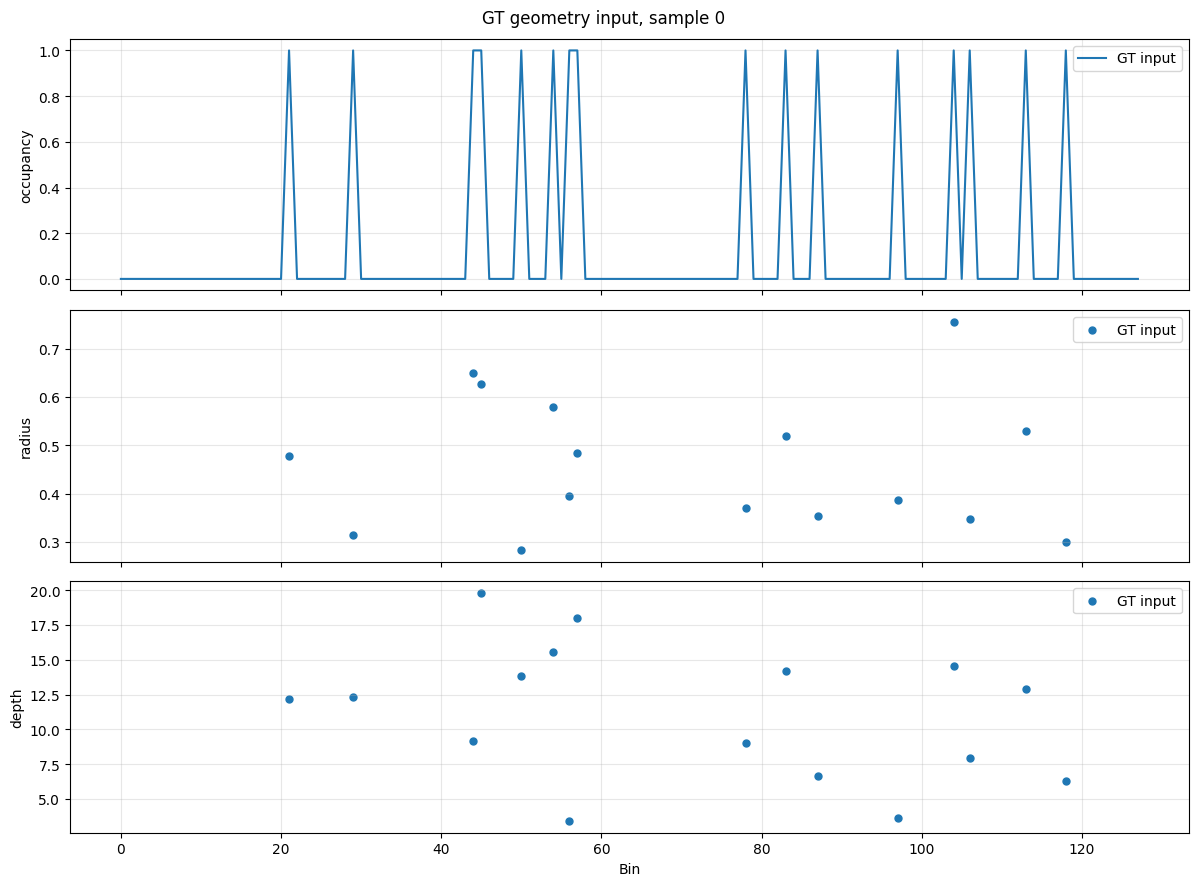

In [11]:
sample_idx = VISION_SAMPLE_IDX
bins = np.arange(vision_a.shape[1])
if INFERENCE_SHOW_IMAGES:
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    names = ["occupancy", "radius", "depth"]
    occupied = vision_a[sample_idx, :, 0].detach().cpu().numpy() > 0.5
    for j, ax in enumerate(axes):
        values = vision_a[sample_idx, :, j].detach().cpu().numpy()
        if j == 0:
            ax.plot(bins, values, label="GT input")
        else:
            ax.scatter(bins[occupied], values[occupied], label="GT input", s=25)
        ax.set_ylabel(names[j])
        ax.grid(True, alpha=0.3)
        ax.legend()
    axes[-1].set_xlabel("Bin")
    fig.suptitle(f"GT geometry input, sample {sample_idx}")
    plt.tight_layout()
    plt.show()


## 3. Image pair and known correspondences

The images are shown for reference. Only GT-bin maps are passed to the model.


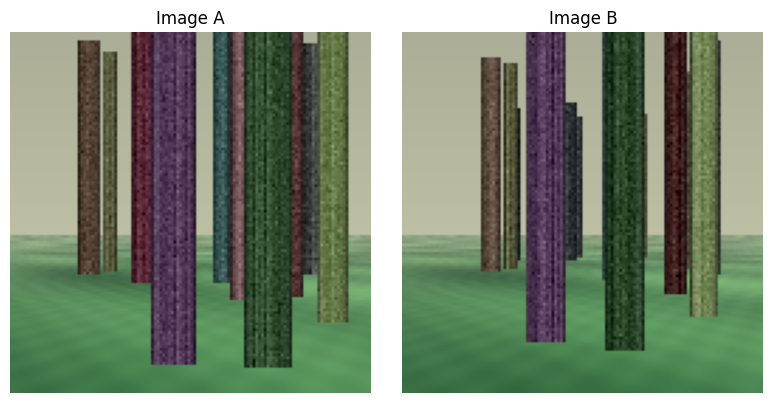

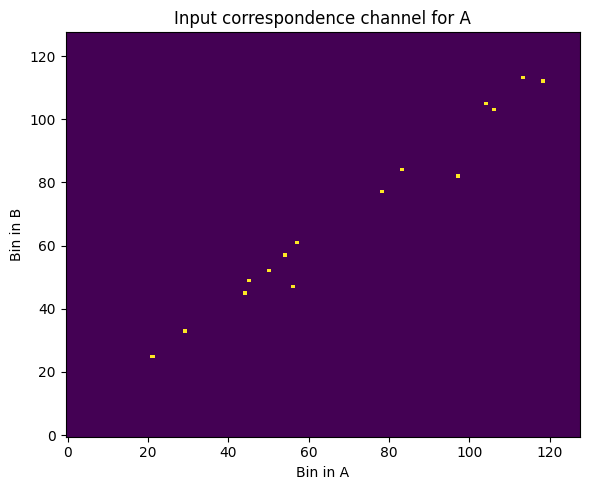

In [12]:
if INFERENCE_SHOW_IMAGES:
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(img_a[VISION_SAMPLE_IDX].cpu().permute(1, 2, 0))
    axes[0].set_title("Image A")
    axes[0].axis("off")
    axes[1].imshow(img_b[VISION_SAMPLE_IDX].cpu().permute(1, 2, 0))
    axes[1].set_title("Image B")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    if model.backbone.patch_embed.proj.in_channels == 4:
        map_a, _ = gt_correspondence_maps(vision_a, vision_b)
        shown_map = map_a[sample_idx].cpu().numpy()
        if not model.use_gt_correspondences:
            shown_map = np.zeros_like(shown_map)
        fig, ax = plt.subplots(figsize=(6, 5))
        ax.imshow(shown_map, origin="lower", interpolation="nearest", aspect="auto", vmin=0, vmax=1)
        ax.set_xlabel("Bin in A")
        ax.set_ylabel("Bin in B")
        ax.set_title("Input correspondence channel for A")
        plt.tight_layout()
        plt.show()


## 4. Relative pose


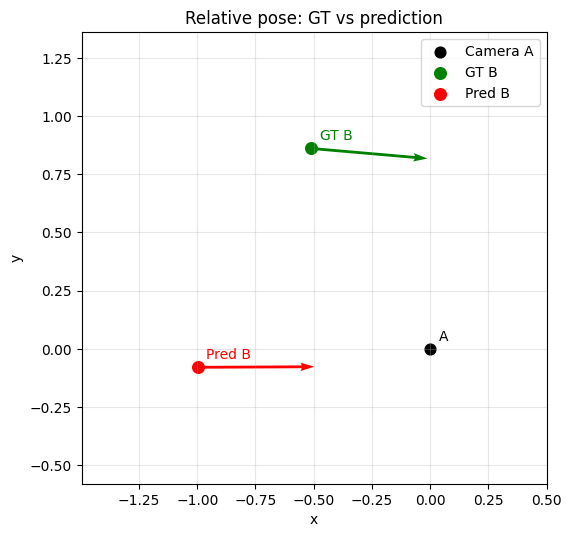

In [13]:
gt_pose = pose_ab[VISION_SAMPLE_IDX].detach().cpu()
pred_pose_sample = pred_pose[VISION_SAMPLE_IDX].detach().cpu()
if INFERENCE_SHOW_TEXT:
    print("GT :", pose_to_text(gt_pose))
    print("Pred:", pose_to_text(pred_pose_sample))
if INFERENCE_SHOW_IMAGES:
    plot_relative_pose(pose_ab[VISION_SAMPLE_IDX], pred_pose[VISION_SAMPLE_IDX])


## 5. Training history (optional)

Plot epoch-aligned loss curves stored in the selected checkpoint.


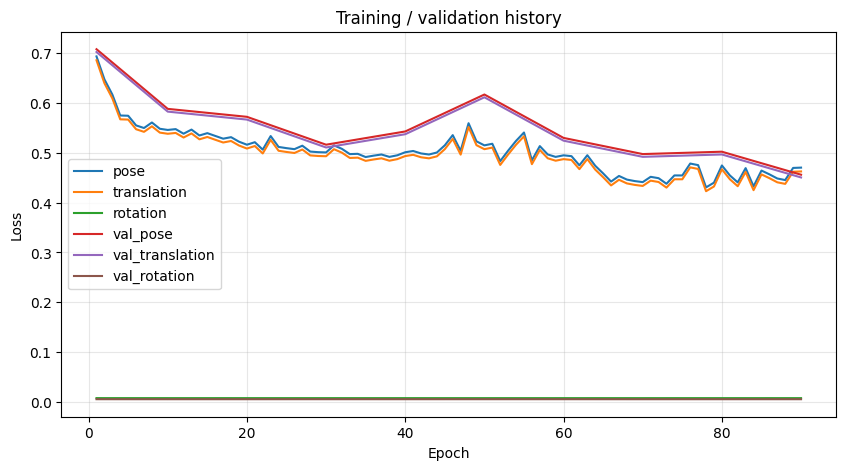

In [14]:
# train_v2 stores history as a dictionary of epoch-aligned metrics.
if isinstance(history, dict):
    epochs = history.get("epoch", [])
    val_epochs = history.get("val_epoch", [])
    train_keys = ["loss", "vision_loss", "pose_loss", "correspondence_loss", "pose", "translation", "rotation"]
    val_keys = ["val_total", "val_vision", "val_correspondence", "val_depth_structure", "val_depth_delta", "val_pose", "val_translation", "val_rotation"]
    plt.figure(figsize=(10, 5))
    plotted = False
    for keys, xs, prefix in [(train_keys, epochs, "train"), (val_keys, val_epochs, "val")]:
        for key in keys:
            ys = history.get(key, [])
            if len(xs) and len(ys) == len(xs):
                plt.plot(xs, ys, label=key)
                plotted = True
    if plotted:
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Training / validation history")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()
    else:
        plt.close()
        print("History present, but no matching epoch-aligned loss curves.")
else:
    print("No training history stored in the selected checkpoint.")


## 6. Compare checkpoints (optional)


In [17]:
# Optional: evaluate several checkpoints on exactly the same dataset.
# Add paths below, then run this cell.
COMPARE_CHECKPOINTS = {
     "GT bins, with matches": Path("arrhenius_runs/slurm_long_run_gt_bins_corr/checkpoints/best.pt"),
     "GT bins, no matches": Path("arrhenius_runs/slurm_long_run_gt_bins/checkpoints/best.pt"),
     "GT bins, no matches lr e-4": Path("arrhenius_runs/slurm_long_run_gt_bins_lr_e4/checkpoints/best.pt"),
}

comparison_results = {}
for label, path in COMPARE_CHECKPOINTS.items():
    print("\n" + label)
    candidate, candidate_checkpoint = load_gt_pose_checkpoint(path, DEVICE)
    if candidate_checkpoint.get("args", {}).get("img_size", IMG_SIZE) != checkpoint.get("args", {}).get("img_size", IMG_SIZE):
        raise ValueError("Comparison checkpoints must use the same dataset image size.")
    comparison_results[label] = evaluate_pose(candidate, infer_loader, DEVICE)
    del candidate

if comparison_results:
    from IPython.display import Markdown, display
    rows = ["| Run | T mean | T median | T P90 | Yaw mean | Yaw median | Yaw P90 |",
            "|---|---:|---:|---:|---:|---:|---:|"]
    for label, result in comparison_results.items():
        keys = ["translation_mean", "translation_median", "translation_p90",
                "yaw_mean", "yaw_median", "yaw_p90"]
        rows.append("| " + label + " | " + " | ".join(f"{result[k]:.2f}°" for k in keys) + " |")
    display(Markdown("\n".join(rows)))



GT bins, with matches
Loaded checkpoint: arrhenius_runs/slurm_long_run_gt_bins_corr/checkpoints/best.pt
Checkpoint epoch: 90
Condition: GT bins + GT correspondences, 4 channels
Model parameters: 4,595,593
CAMERA POSE PERFORMANCE

Test pairs:             482
Successful poses:       482
Prediction failures:    0
Success rate:           1.000

TRANSLATION DIRECTION ERROR
----------------------------------------
Mean:                   46.08°
Median:                 29.33°
P90:                    121.85°

YAW ERROR
----------------------------------------
Mean:                   3.80°
Median:                 2.25°
P90:                    9.66°

ACCURACY THRESHOLDS
----------------------------------------
<  5°: T= 25.9% | Yaw= 70.7%
< 10°: T= 33.8% | Yaw= 90.9%
< 20°: T= 44.0% | Yaw= 98.5%
< 30°: T= 50.2% | Yaw= 99.8%

GT bins, no matches
Loaded checkpoint: arrhenius_runs/slurm_long_run_gt_bins/checkpoints/best.pt
Checkpoint epoch: 150
Condition: GT bins, 3 channels
Model parameters: 4,58

| Run | T mean | T median | T P90 | Yaw mean | Yaw median | Yaw P90 |
|---|---:|---:|---:|---:|---:|---:|
| GT bins, with matches | 46.08° | 29.33° | 121.85° | 3.80° | 2.25° | 9.66° |
| GT bins, no matches | 48.19° | 32.15° | 121.87° | 3.79° | 2.35° | 9.66° |
| GT bins, no matches lr e-4 | 49.16° | 31.46° | 126.41° | 3.82° | 2.33° | 9.71° |